In [1]:
# ==============================================================================
# CELL 0: IMPORTS & CONFIGURATION
# ==============================================================================
%load_ext autoreload
%autoreload 2
import os
import sys
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors

# --- PATH RESOLUTION ---
# Add project root and tools directory to system path to locate custom modules
PROJ_ROOT = os.path.abspath("..")
TOOLS_DIR = os.path.join(PROJ_ROOT, "tools")

if PROJ_ROOT not in sys.path:
    sys.path.append(PROJ_ROOT)
if TOOLS_DIR not in sys.path:
    sys.path.append(TOOLS_DIR)

# Import local tools and fake_spectra modules
import utils
import fake_spectra.spectra as spectra
import fake_spectra.abstractsnapshot as absn
import fake_spectra.unitsystem as unitsystem
import fake_spectra.gas_properties as gas_properties

# --- STYLE CONFIGURATION ---
def matplotlib_default_config():
    """Returns the default dictionary configurations for publication-ready plots."""
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False, 
        'figure.frameon': True,
        'axes.linewidth': 2., 
        "axes.titlesize" : 20, 
        "axes.labelsize" : 20,
        "legend.fontsize" : 12, 
        'lines.linewidth': 2.5,
        'xtick.direction': 'in', 
        'ytick.direction': 'in',
        'xtick.top': True, 
        'ytick.right': True,
        'xtick.labelsize': 18, 
        'ytick.labelsize': 18
    }
    return font, rcnew

# Apply interactive backend and style
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [2]:
%autoreload

In [3]:
# ==============================================================================
# CELL 1: TARGET CONFIGURATION
# ==============================================================================
BASE_PATH = "/home/STORAGE/MN5_resims/fiducial/hydro_output"
SNAP_NUM = 94
SIM_TYPE = "MN5"

# --- SKEWER CONFIGURATION ---
# Axis mapping: 1 = X, 2 = Y, 3 = Z
LOS_AXIS = 1

# Coordinates in code units (cMpc/h)
# Box is 500 cMpc/h. 
# For LOS_AXIS = 1 (X): Target Coord A -> Y, Target Coord B -> Z
# For LOS_AXIS = 2 (Y): Target Coord A -> X, Target Coord B -> Z
# For LOS_AXIS = 3 (Z): Target Coord A -> X, Target Coord B -> Y
TARGET_COORD_A = 219.0 
TARGET_COORD_B = 250.0 

# Slice thickness for the 2D projection (in cMpc/h)
SLICE_THICKNESS = 1.0 

# Initialize Context. 
# NOTE: This automatically triggers the MN5 monkey-patch inside utils.py!
ctx = utils.SimulationContext(BASE_PATH, SNAP_NUM, sim_type=SIM_TYPE)
snap_dir = os.path.join(BASE_PATH, f"snapdir_{ctx.snap_num}")

# MN5 uses the "snapshot_" prefix
first_file = os.path.join(snap_dir, f"snapshot_{ctx.snap_num}.0.hdf5")

# Extract BoxSize dynamically from the header
with h5py.File(first_file, 'r') as f:
    BOX_SIZE = f['Header'].attrs['BoxSize']

print(f"Simulation Box Size : {BOX_SIZE:.2f} cMpc/h")
print(f"Targeting Axis      : {LOS_AXIS}")
print(f"Target Coordinates  : ({TARGET_COORD_A}, {TARGET_COORD_B})")

Simulation Box Size : 500.00 cMpc/h
Targeting Axis      : 1
Target Coordinates  : (219.0, 250.0)


In [4]:
# ==============================================================================
# CELL 2: LOAD PARTICLE SLICE (MEMORY OPTIMIZED)
# ==============================================================================
print("Iterating through snapshot chunks to extract the slice...")

# Pre-calculate slice boundaries based on the perpendicular axis
slice_min = TARGET_COORD_B - (SLICE_THICKNESS / 2.0)
slice_max = TARGET_COORD_B + (SLICE_THICKNESS / 2.0)

pos_list = []
rho_list = []

# Retrieve all snapshot chunks
file_list = glob.glob(os.path.join(snap_dir, f"snapshot_{ctx.snap_num}.*.hdf5"))

for h5_file in file_list:
    with h5py.File(h5_file, 'r') as f:
        if 'PartType0' not in f:
            continue
            
        pos = f['PartType0']['Coordinates'][:]
        rho = f['PartType0']['Density'][:]
        
        # Determine the slicing mask based on the line-of-sight (LOS) axis
        if LOS_AXIS == 1:   # Map XY, slice along Z
            mask = (pos[:, 2] >= slice_min) & (pos[:, 2] <= slice_max)
        elif LOS_AXIS == 2: # Map XY, slice along Z
            mask = (pos[:, 2] >= slice_min) & (pos[:, 2] <= slice_max)
        elif LOS_AXIS == 3: # Map XZ, slice along Y
            mask = (pos[:, 1] >= slice_min) & (pos[:, 1] <= slice_max)

        if np.any(mask):
            pos_list.append(pos[mask])
            rho_list.append(rho[mask])

# Concatenate collected data
pos_slice = np.vstack(pos_list)
rho_slice = np.concatenate(rho_list)

print(f"Found {len(pos_slice):,} gas particles in the {SLICE_THICKNESS} cMpc/h slice.")

Iterating through snapshot chunks to extract the slice...
Found 276,857 gas particles in the 1.0 cMpc/h slice.


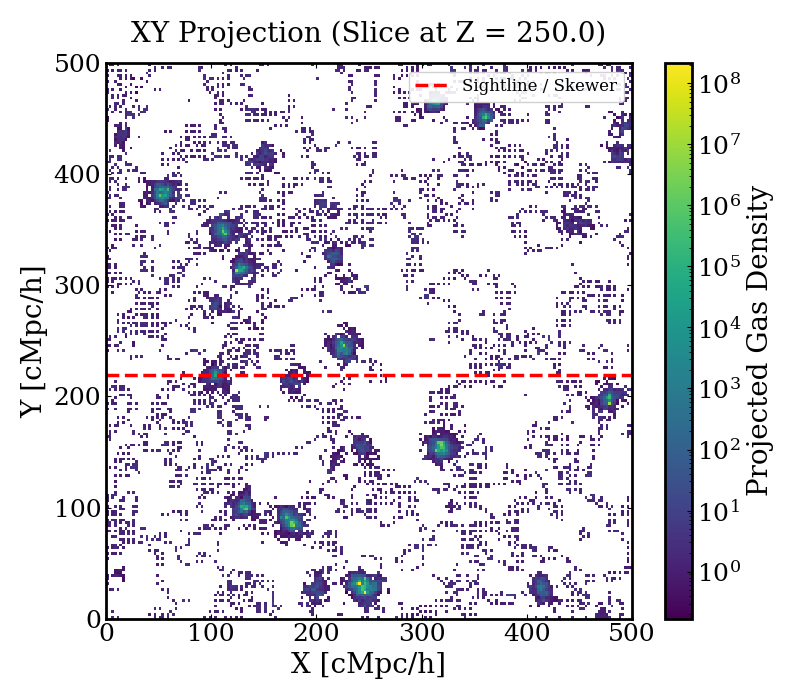

In [5]:
# ==============================================================================
# CELL 3: 2D GAS DENSITY MAP & SKEWER TRAJECTORY
# ==============================================================================
fig_map, ax_map = plt.subplots(figsize=(8, 7))

# Setup coordinates and labels based on the projection plane
if LOS_AXIS == 1:
    x_map = pos_slice[:, 0]
    y_map = pos_slice[:, 1]
    xlabel, ylabel = 'X [cMpc/h]', 'Y [cMpc/h]'
    title = f'XY Projection (Slice at Z = {TARGET_COORD_B:.1f})'
    skewer_x = [0, BOX_SIZE]
    skewer_y = [TARGET_COORD_A, TARGET_COORD_A]
elif LOS_AXIS == 2:
    x_map = pos_slice[:, 0]
    y_map = pos_slice[:, 1]
    xlabel, ylabel = 'X [cMpc/h]', 'Y [cMpc/h]'
    title = f'XY Projection (Slice at Z = {TARGET_COORD_B:.1f})'
    skewer_x = [TARGET_COORD_A, TARGET_COORD_A]
    skewer_y = [0, BOX_SIZE]
elif LOS_AXIS == 3:
    x_map = pos_slice[:, 0]
    y_map = pos_slice[:, 2]
    xlabel, ylabel = 'X [cMpc/h]', 'Z [cMpc/h]'
    title = f'XZ Projection (Slice at Y = {TARGET_COORD_B:.1f})'
    skewer_x = [TARGET_COORD_A, TARGET_COORD_A]
    skewer_y = [0, BOX_SIZE]

# Generate 2D Histogram for projected gas density
h = ax_map.hist2d(x_map, y_map, bins=200, weights=rho_slice, norm=colors.LogNorm(), cmap='viridis')

# Overlay the Skewer sightline
ax_map.plot(skewer_x, skewer_y, color='red', ls='--', lw=2.5, label='Sightline / Skewer')

# Plot aesthetics
cbar = fig_map.colorbar(h[3], ax=ax_map)
cbar.set_label(r'Projected Gas Density')
ax_map.set_xlabel(xlabel)
ax_map.set_ylabel(ylabel)
ax_map.set_xlim(0, BOX_SIZE)
ax_map.set_ylim(0, BOX_SIZE)
ax_map.set_title(title, pad=15)
ax_map.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.show()

In [6]:
# ==============================================================================
# CELL 4: SKEWER EXTRACTION (CLEAN CALL TO UTILS)
# ==============================================================================
print("Configuring MN5 Units (Mpc/h) and Initializing Skewer...")

# Setup skewer coordinates array
cofm_array = np.zeros((1, 3))
if LOS_AXIS == 1:
    cofm_array[0, 1] = TARGET_COORD_A
    cofm_array[0, 2] = TARGET_COORD_B
elif LOS_AXIS == 2:
    cofm_array[0, 0] = TARGET_COORD_A
    cofm_array[0, 2] = TARGET_COORD_B
elif LOS_AXIS == 3:
    cofm_array[0, 0] = TARGET_COORD_A
    cofm_array[0, 1] = TARGET_COORD_B

axis_array = np.array([LOS_AXIS], dtype=np.int32)
save_file = "temp_single_skewer.hdf5"

if os.path.exists(save_file):
    os.remove(save_file)

# Force UnitLength to Mpc/h (10^24 cm) for MN5 compatibility
mn5_units = unitsystem.UnitSystem(
    UnitLength_in_cm=3.085678e24, 
    UnitMass_in_g=1.989e43,        
    UnitVelocity_in_cm_per_s=1e5   
)

# Initialize Spectra extraction engine. 
# Because ctx was instantiated in Cell 1, utils.py already patched the missing HSML!
ss = spectra.Spectra(
    int(ctx.snap_num), 
    ctx.base_path, 
    cofm=cofm_array, 
    axis=axis_array, 
    res=10.0, 
    savefile=save_file, 
    reload_file=True,
    kernel=None,        
    MPI=None,           
    quiet=False,        
    filter_mode="None", 
    dla_phys_thresh="auto",
    units=mn5_units    
)

# Extract optical depth (tau) and compute transmitted flux
tau = ss.get_tau("H", 1, 1215)[0]
flux = np.exp(-tau)

# Extract Column Density (N_HI)
n_hi_col = ss.get_col_density("H", 1)[0]
total_n_hi = np.sum(n_hi_col)
log_n_hi = np.log10(total_n_hi) if total_n_hi > 0 else 0.0

# Generate kinematic velocity axis
nbins = ss.nbins
vmax = ss.vmax
vel_axis = np.arange(nbins) * (vmax / nbins)

# Clean up temporary file
if os.path.exists(save_file): 
    os.remove(save_file)

print("\nExtraction complete! Ready for plotting.")

Configuring MN5 Units (Mpc/h) and Initializing Skewer...
Reloading from snapshot (will save to:  /home/STORAGE/MN5_resims/fiducial/hydro_output/snapdir_094/temp_single_skewer.hdf5  )
1  sightlines. resolution:  10.000813673834802  z= 2.978397693934533
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done

Extraction complete! Ready for plotting.


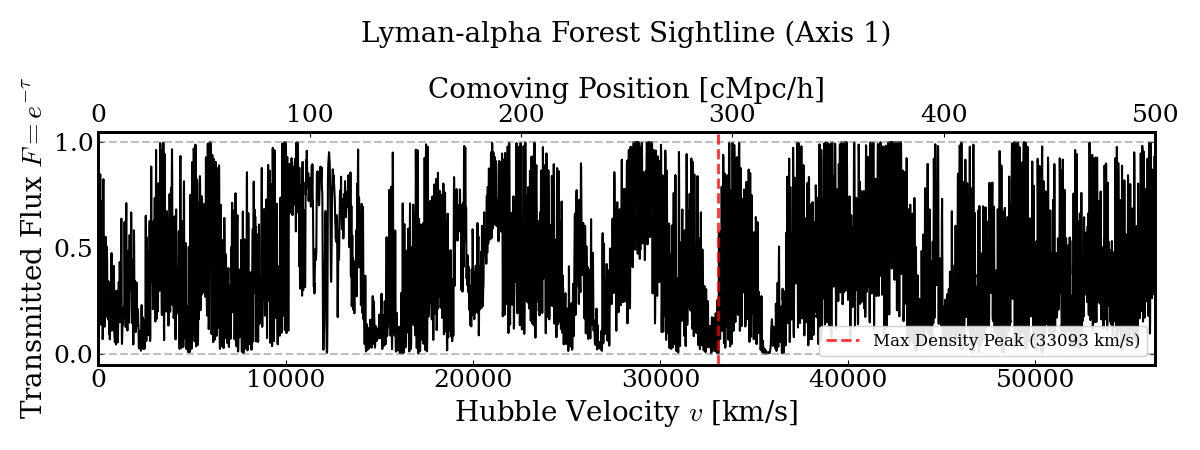

In [7]:
# ==============================================================================
# CELL 5: TRANSMITTED FLUX SPECTRUM PLOT
# ==============================================================================
fig_spec, ax_spec = plt.subplots(figsize=(12, 4.5))

# Plot the main absorption spectrum
ax_spec.plot(vel_axis, flux, color='black', lw=1.5)

# Add horizontal reference lines for 0 and 1 flux
ax_spec.axhline(0, color='gray', ls='--', lw=1.5, alpha=0.5)
ax_spec.axhline(1, color='gray', ls='--', lw=1.5, alpha=0.5)

# --- Identify and mark the densest region (Maximum Absorption) ---
max_tau_idx = np.argmax(tau)
peak_velocity = vel_axis[max_tau_idx]

# Draw a vertical red dashed line at the peak density location
ax_spec.axvline(peak_velocity, color='red', ls='--', lw=2.0, alpha=0.8, 
                label=f'Max Density Peak ({peak_velocity:.0f} km/s)')

# Set axis limits
ax_spec.set_xlim(0, vmax)
ax_spec.set_ylim(-0.05, 1.05)

# Labels and title
ax_spec.set_xlabel(r'Hubble Velocity $v$ [km/s]')
ax_spec.set_ylabel(r'Transmitted Flux $F = e^{-\tau}$')
ax_spec.set_title(f'Lyman-alpha Forest Sightline (Axis {LOS_AXIS})', pad=25)
ax_spec.legend(loc='lower right', framealpha=0.9)

# Create a secondary (twin) X-axis for comoving position
ax_spatial = ax_spec.twiny()
ax_spatial.plot(np.linspace(0, BOX_SIZE, nbins), flux, alpha=0.0) # Invisible plot to align ticks
ax_spatial.set_xlim(0, BOX_SIZE)
ax_spatial.set_xlabel(r'Comoving Position [cMpc/h]')

plt.tight_layout()
plt.show()

In [8]:
# --- PRINT THE COLUMN DENSITY SUMMARY ---
print("\n" + "="*65)
print(" SKEWER COLUMN DENSITY SUMMARY (H I)")
print("="*65)
print(f" Total N_HI  : {total_n_hi:.3e} cm^-2")
print(f" Log N_HI    : {log_n_hi:.3f}")

if log_n_hi >= 20.3:
    print(f" Class       : DLA (Damped Lyman-alpha System)")
elif log_n_hi >= 17.2:
    print(f" Class       : LLS (Lyman Limit System)")
else:
    print(f" Class       : IGM / Ly-alpha Forest")
print("="*65 + "\n")


 SKEWER COLUMN DENSITY SUMMARY (H I)
 Total N_HI  : 6.017e+16 cm^-2
 Log N_HI    : 16.779
 Class       : IGM / Ly-alpha Forest



Opening the black box: Scanning the intersection cylinder...
Particles intercepted by the cylinder: 1566
Max Neutral Fraction read      : 7.19459e-01
Max Smoothing Length calculated: 2.91856e+00 cMpc/h
Min Smoothing Length calculated: 3.11719e-03 cMpc/h


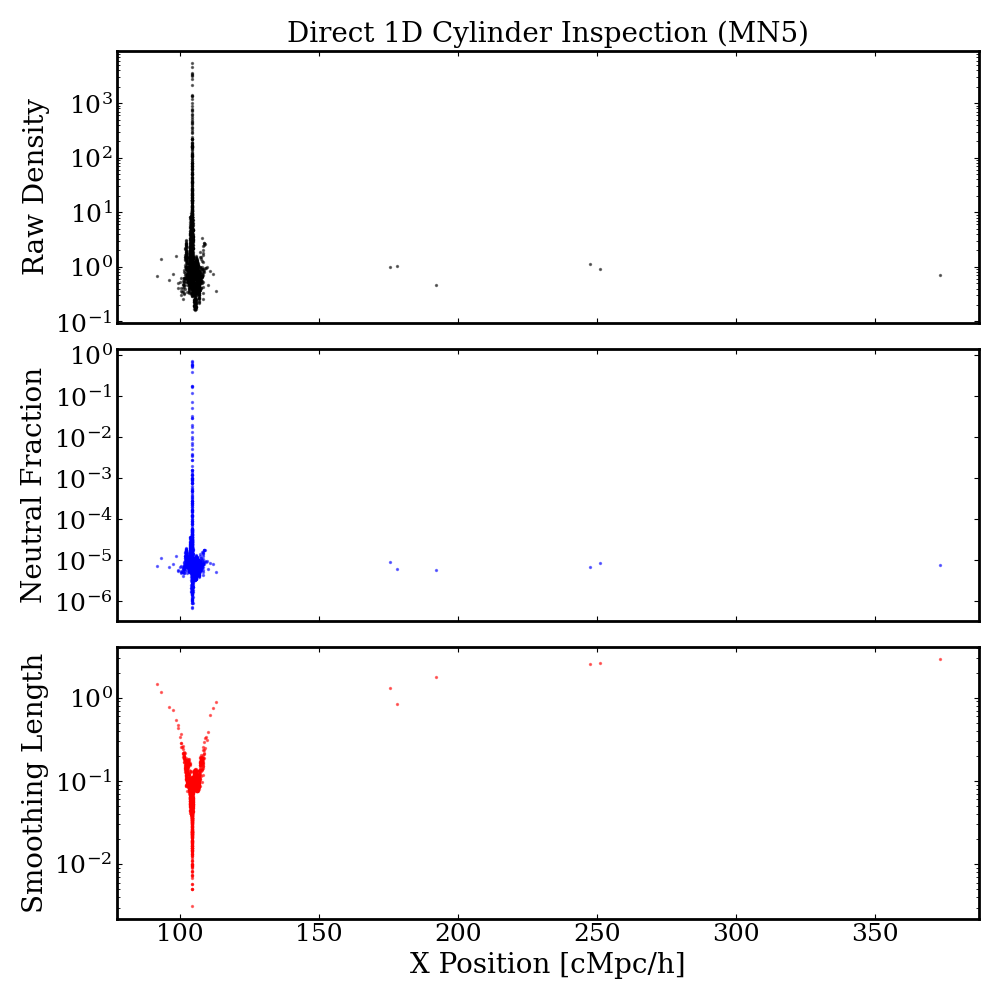

In [9]:
# ==============================================================================
# CELL 6: 1D CYLINDER DIAGNOSTICS (HSML RECONSTRUCTION)
# ==============================================================================
print("Opening the black box: Scanning the intersection cylinder...")

CYLINDER_RADIUS_CMPC = 0.5 

cylinder_x = []
cylinder_rho = []
cylinder_nhi_frac = []
cylinder_hsml = []
cylinder_u = []

for h5_file in file_list:
    with h5py.File(h5_file, 'r') as f:
        if 'PartType0' not in f:
            continue
            
        pos = f['PartType0']['Coordinates'][:]
        
        # Calculate perpendicular distance to the skewer line
        dy = pos[:, 1] - TARGET_COORD_A
        dz = pos[:, 2] - TARGET_COORD_B
        r_perp = np.sqrt(dy**2 + dz**2)
        
        mask = r_perp < CYLINDER_RADIUS_CMPC
        
        if np.any(mask):
            cylinder_x.append(pos[mask, 0])
            
            rho = f['PartType0']['Density'][:]
            cylinder_rho.append(rho[mask])
            
            # --- HSML Reconstruction (Diagnostic parity with utils.py) ---
            if 'Masses' in f['PartType0']:
                mass = f['PartType0']['Masses'][:]
            elif 'Mass' in f['PartType0']:
                mass = f['PartType0']['Mass'][:]
            else:
                mass = np.zeros_like(rho)
                
            # Calculate volume and equivalent radius
            volume = mass / rho
            hsml = (3.0 * volume / (4.0 * np.pi))**(1.0 / 3.0)
            cylinder_hsml.append(hsml[mask])
                
            # --- Neutral Fraction ---
            if 'NeutralHydrogenAbundance' in f['PartType0']:
                cylinder_nhi_frac.append(f['PartType0']['NeutralHydrogenAbundance'][mask])
            else:
                cylinder_nhi_frac.append(np.zeros(np.sum(mask)))
                
            # --- Internal Energy ---
            if 'InternalEnergy' in f['PartType0']:
                cylinder_u.append(f['PartType0']['InternalEnergy'][mask])
            else:
                cylinder_u.append(np.zeros(np.sum(mask)))

if len(cylinder_x) == 0:
    print("[CRITICAL WARNING] No gas particles found in the geometric cylinder!")
else:
    x_arr = np.concatenate(cylinder_x)
    rho_arr = np.concatenate(cylinder_rho)
    nhi_arr = np.concatenate(cylinder_nhi_frac)
    hsml_arr = np.concatenate(cylinder_hsml)
    u_arr = np.concatenate(cylinder_u)
    
    print(f"Particles intercepted by the cylinder: {len(x_arr)}")
    print(f"Max Neutral Fraction read      : {np.max(nhi_arr):.5e}")
    print(f"Max Smoothing Length calculated: {np.max(hsml_arr):.5e} cMpc/h")
    print(f"Min Smoothing Length calculated: {np.min(hsml_arr):.5e} cMpc/h")
    
    fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
    
    axes[0].scatter(x_arr, rho_arr, s=2, alpha=0.5, color='black')
    axes[0].set_ylabel("Raw Density")
    axes[0].set_yscale('log')
    axes[0].set_title("Direct 1D Cylinder Inspection (MN5)")
    
    axes[1].scatter(x_arr, nhi_arr, s=2, alpha=0.5, color='blue')
    axes[1].set_ylabel("Neutral Fraction")
    axes[1].set_yscale('symlog', linthresh=1e-10)
    
    axes[2].scatter(x_arr, hsml_arr, s=2, alpha=0.5, color='red')
    axes[2].set_ylabel("Smoothing Length")
    axes[2].set_xlabel("X Position [cMpc/h]")
    axes[2].set_yscale('log')
    
    plt.tight_layout()
    plt.show()

Running extraction with filter_mode='DLAs'...
Running extraction with filter_mode='No_DLAs'...
Generating comparison plot...


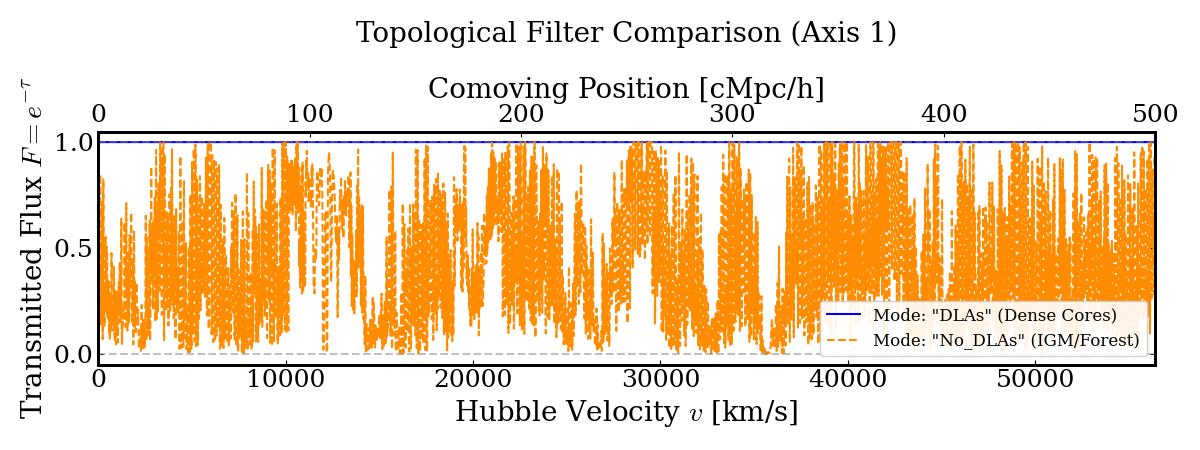

In [10]:
# ==============================================================================
# CELL 7: FILTER MODE COMPARISON (DLAs vs No_DLAs)
# ==============================================================================
print("Running extraction with filter_mode='DLAs'...")
save_file_dla = "temp_skewer_dla.hdf5"
if os.path.exists(save_file_dla): os.remove(save_file_dla)

# 1. Extract only the DLA regions
ss_dla = spectra.Spectra(
    int(ctx.snap_num), 
    ctx.base_path, 
    cofm=cofm_array, 
    axis=axis_array, 
    res=10.0, 
    savefile=save_file_dla, 
    reload_file=True,
    kernel=None,        
    MPI=None,           
    quiet=True,         # Suppress terminal output for this run
    filter_mode="DLAs", 
    dla_phys_thresh="auto",
    units=mn5_units    
)

tau_dla = ss_dla.get_tau("H", 1, 1215)[0]
flux_dla = np.exp(-tau_dla)
if os.path.exists(save_file_dla): os.remove(save_file_dla)

# ------------------------------------------------------------------------------
print("Running extraction with filter_mode='No_DLAs'...")
save_file_nodla = "temp_skewer_nodla.hdf5"
if os.path.exists(save_file_nodla): os.remove(save_file_nodla)

# 2. Extract only the IGM/Forest regions (excluding DLAs)
ss_nodla = spectra.Spectra(
    int(ctx.snap_num), 
    ctx.base_path, 
    cofm=cofm_array, 
    axis=axis_array, 
    res=10.0, 
    savefile=save_file_nodla, 
    reload_file=True,
    kernel=None,        
    MPI=None,           
    quiet=True,        
    filter_mode="No_DLAs", 
    dla_phys_thresh="auto",
    units=mn5_units    
)

tau_nodla = ss_nodla.get_tau("H", 1, 1215)[0]
flux_nodla = np.exp(-tau_nodla)
if os.path.exists(save_file_nodla): os.remove(save_file_nodla)

# ------------------------------------------------------------------------------
print("Generating comparison plot...")

fig_comp, ax_comp = plt.subplots(figsize=(12, 4.5))

# Plot DLAs (Blue, Solid) and No_DLAs (Orange, Dashed)
ax_comp.plot(vel_axis, flux_dla, color='blue', lw=1.5, label='Mode: "DLAs" (Dense Cores)')
ax_comp.plot(vel_axis, flux_nodla, color='darkorange', lw=1.5, ls='--', label='Mode: "No_DLAs" (IGM/Forest)')

# Add horizontal reference lines
ax_comp.axhline(0, color='gray', ls='--', lw=1.5, alpha=0.5)
ax_comp.axhline(1, color='gray', ls='--', lw=1.5, alpha=0.5)

# Set axis limits
ax_comp.set_xlim(0, vmax)
ax_comp.set_ylim(-0.05, 1.05)

# Labels and title
ax_comp.set_xlabel(r'Hubble Velocity $v$ [km/s]')
ax_comp.set_ylabel(r'Transmitted Flux $F = e^{-\tau}$')
ax_comp.set_title(f'Topological Filter Comparison (Axis {LOS_AXIS})', pad=25)
ax_comp.legend(loc='lower right', framealpha=0.9)

# Create a secondary (twin) X-axis for comoving position
ax_spatial_comp = ax_comp.twiny()
ax_spatial_comp.plot(np.linspace(0, BOX_SIZE, nbins), flux_dla, alpha=0.0) 
ax_spatial_comp.set_xlim(0, BOX_SIZE)
ax_spatial_comp.set_xlabel(r'Comoving Position [cMpc/h]')

plt.tight_layout()
plt.show()